## Seoul Bike Sharing Demand

Bike-sharing systems have become increasingly important in urban environments as a sustainable and efficient mode of transportation. Accurately predicting bike demand is essential for optimizing resource allocation, such as bike redistribution and maintenance.

This project uses the ***Seoul Bike Sharing Demand*** dataset, which contains hourly records of the number of rented bikes along with weather conditions and time-related features.

The objective of this project is to build a model that can predict bike rental demand based on these features. Additionally, the project aims to compare the performance of classical statistical time series models (such as ARIMA) with a supervised machine learning algorithm (Random Forest) to determine which approach provides better predictive accuracy on this dataset.

Target variable:
- **Rented Bike Count** – the number of bikes rented in a given hour

Dataset source: https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand

In [51]:
library(tidyverse)
library(tidymodels)
library(ggplot2)
library(readr)
library(dplyr)
library(forecast)
library(vars)
library(lubridate)
library(zoo)
library(corrplot)

seoul_bike_data = 
    read_csv(
        "SeoulBikeData.csv",
        locale = locale(encoding = "ISO-8859-1"),
        col_types = cols(
        Date = col_date(format = "%d/%m/%Y")
    ),
    show_col_types = FALSE
)

In [2]:
head(seoul_bike_data)

Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>
2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0,0,0,Winter,No Holiday,Yes
2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0,0,0,Winter,No Holiday,Yes
2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0,0,0,Winter,No Holiday,Yes
2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0,0,0,Winter,No Holiday,Yes
2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0,0,0,Winter,No Holiday,Yes
2017-12-01,100,5,-6.4,37,1.5,2000,-18.7,0,0,0,Winter,No Holiday,Yes


## Data Preprocessing
The dataset is relatively clean, with no missing values or unrealistic values. However, it contains a variable called ***Functioning Day***, which indicates whether the bike system was operational.

For days marked as "***No***", the number of rented bikes is consistently zero across all hours. These observations do not reflect actual demand, therefore they were removed from the dataset.

In total, 12 full days with no operation and 1 partially affected day were excluded.


In [3]:
summary(seoul_bike_data)

      Date            Rented Bike Count      Hour       Temperature(°C) 
 Min.   :2017-12-01   Min.   :   0.0    Min.   : 0.00   Min.   :-17.80  
 1st Qu.:2018-03-02   1st Qu.: 191.0    1st Qu.: 5.75   1st Qu.:  3.50  
 Median :2018-06-01   Median : 504.5    Median :11.50   Median : 13.70  
 Mean   :2018-06-01   Mean   : 704.6    Mean   :11.50   Mean   : 12.88  
 3rd Qu.:2018-08-31   3rd Qu.:1065.2    3rd Qu.:17.25   3rd Qu.: 22.50  
 Max.   :2018-11-30   Max.   :3556.0    Max.   :23.00   Max.   : 39.40  
  Humidity(%)    Wind speed (m/s) Visibility (10m) Dew point temperature(°C)
 Min.   : 0.00   Min.   :0.000    Min.   :  27     Min.   :-30.600          
 1st Qu.:42.00   1st Qu.:0.900    1st Qu.: 940     1st Qu.: -4.700          
 Median :57.00   Median :1.500    Median :1698     Median :  5.100          
 Mean   :58.23   Mean   :1.725    Mean   :1437     Mean   :  4.074          
 3rd Qu.:74.00   3rd Qu.:2.300    3rd Qu.:2000     3rd Qu.: 14.800          
 Max.   :98.00   Max.   :7.

**No missing values or data parsing issues**

In [4]:
colSums(is.na(seoul_bike_data))

problems(seoul_bike_data)

Date         Rented Bike Count                      Hour 
                        0                         0                         0 
          Temperature(°C)               Humidity(%)          Wind speed (m/s) 
                        0                         0                         0 
         Visibility (10m) Dew point temperature(°C)   Solar Radiation (MJ/m2) 
                        0                         0                         0 
             Rainfall(mm)             Snowfall (cm)                   Seasons 
                        0                         0                         0 
                  Holiday           Functioning Day 
                        0                         0

row,col,expected,actual,file
<int>,<int>,<chr>,<chr>,<chr>


The distribution of the ***rented bike count*** is visualized using a jitter plot. 
The values appear to be reasonably spread, with **no obvious extreme outliers**. 

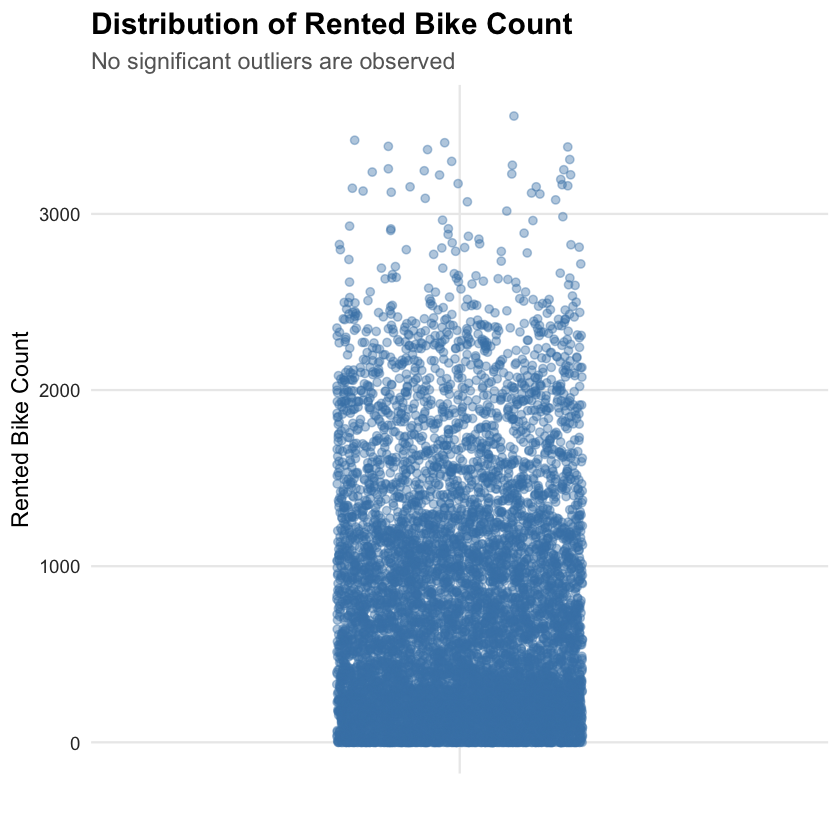

In [5]:
ggplot(seoul_bike_data, aes(x = "", y = `Rented Bike Count`)) +
    geom_jitter(width = 0.2, alpha = 0.4, color = "steelblue") +
    labs(
        title = "Distribution of Rented Bike Count",
        subtitle = "No significant outliers are observed",
        x = "",
        y = "Rented Bike Count"
    ) +
theme_minimal(base_size = 14) +
theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
)

Examination of the ***Functioning Day*** column and filtering of the dataset by excluding all observations corresponding to days where ***Functioning Day*** is "No". A total of 12 full days and one partially affected day were excluded, with the partially affected day removed entirely to ensure consistency.

In [6]:
daily_status = seoul_bike_data %>%
    group_by(Date) %>%
    summarise(
        all_no = all(`Functioning Day` == "No"),
        all_yes = all(`Functioning Day` == "Yes"),
        .groups = "drop"
    )

In [7]:
daily_status %>%
    summarise(
        functioning_days = sum(all_yes),
        non_functioning_days = sum(all_no),
        mixed_days = sum(!all_no & !all_yes)
    )

functioning_days,non_functioning_days,mixed_days
<int>,<int>,<int>
352,12,1


In [8]:
seoul_bike_data %>%
group_by(Date) %>%
summarise(
total_rentals = sum(`Rented Bike Count`),
status = case_when(
    all(`Functioning Day` == "No") ~ "non functioning day",
    all(`Functioning Day` == "Yes") ~ "functioning",
    TRUE ~ "mixed day"
),
    .groups = "drop"
) %>%
filter(status != "functioning")

Date,total_rentals,status
<date>,<dbl>,<chr>
2018-04-11,0,non functioning day
2018-05-10,0,non functioning day
2018-09-18,0,non functioning day
2018-09-19,0,non functioning day
2018-09-28,0,non functioning day
2018-09-30,0,non functioning day
2018-10-02,0,non functioning day
2018-10-04,0,non functioning day
2018-10-06,16037,mixed day


In [9]:
seoul_bike_data = seoul_bike_data %>%
  filter(
    `Functioning Day` == "Yes",
    Date != as.Date("2018-10-06")
  )

## Data Exploration

In this section, I used general statistical summaries and visualizations to explore the dataset. Due to its time series nature, particular attention was given to identifying temporal trends and patterns. Additionally, relationships between weather variables and bike rental demand were examined to better understand the underlying factors influencing usage.

### Log-Transformation
The distribution of bike rentals is strongly right-skewed, with most observations at lower values and a long tail of higher counts.
To reduce skewness and stabilize variance, a log transformation (log1p) was applied. This can improve model performance in some cases.

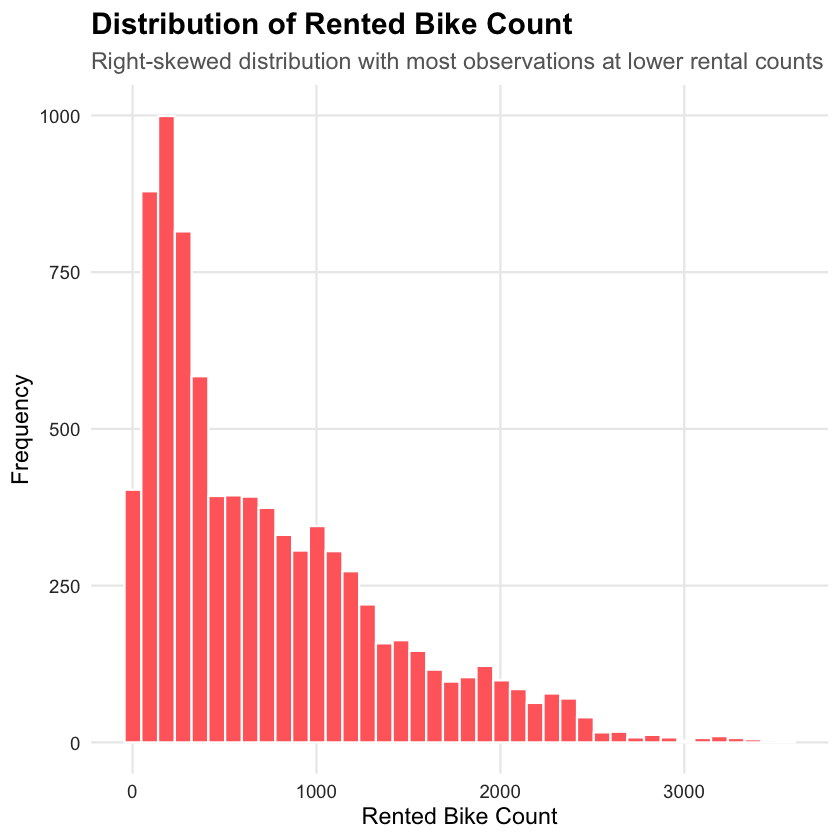

In [10]:
ggplot(seoul_bike_data, aes(x = `Rented Bike Count`)) +
  geom_histogram(bins = 40, fill = "#ff6b6b", color = "white") +
  labs(
    title = "Distribution of Rented Bike Count",
    subtitle = "Right-skewed distribution with most observations at lower rental counts",
    x = "Rented Bike Count",
    y = "Frequency"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

In [11]:
seoul_bike_data$log_bikes = log1p(seoul_bike_data$`Rented Bike Count`)

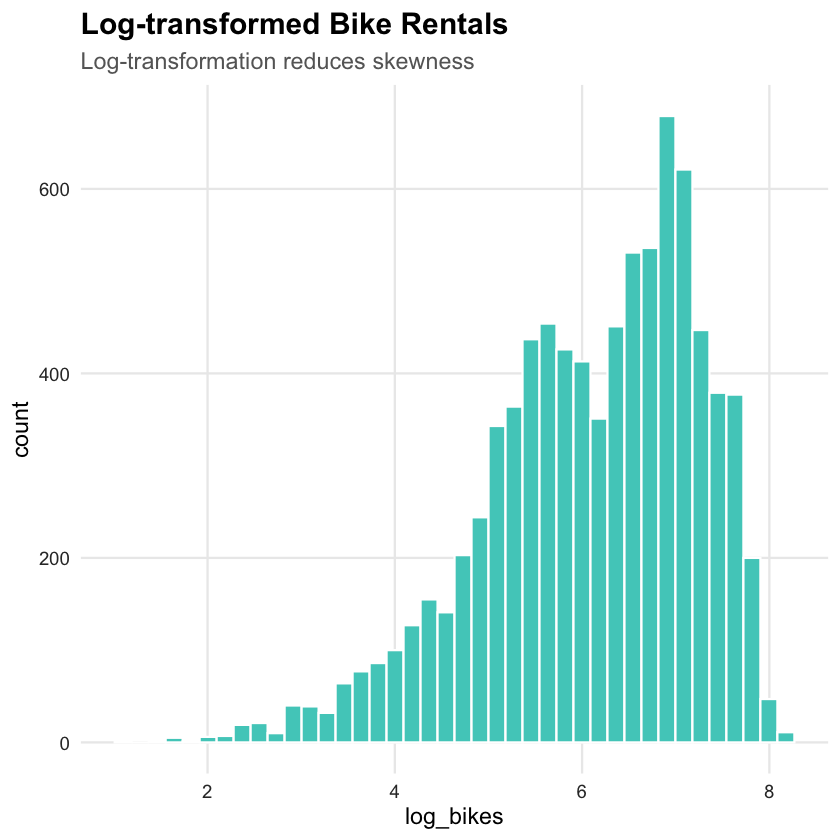

In [12]:
ggplot(seoul_bike_data, aes(x = log_bikes)) +
  geom_histogram(bins = 40, fill = "#4ecdc4", color = "white") +
  labs(
      title = "Log-transformed Bike Rentals",
      subtitle = "Log-transformation reduces skewness"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

Creation of a new categorical variable (***day_type***) based on date information, distinguishing between weekdays, weekends, and holidays.

In [13]:
seoul_bike_data = seoul_bike_data %>%
  mutate(
    Date = as.Date(Date),
    is_weekend = wday(Date, week_start = 1) %in% c(6, 7),
    day_type = case_when(
      Holiday == "Holiday" ~ "Holiday",
      is_weekend ~ "Weekend",
      TRUE ~ "Weekday"
    )
  )

In [14]:
head(seoul_bike_data, 2)

Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,log_bikes,is_weekend,day_type
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<lgl>,<chr>
2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0,0,0,Winter,No Holiday,Yes,5.541264,FALSE,Weekday
2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0,0,0,Winter,No Holiday,Yes,5.323010,FALSE,Weekday


### Daily Rental Patterns

The plots below show clear differences in rental patterns across **day types**.
On weekdays, there are two distinct peaks corresponding to **morning** and **evening commuting hours**.
On weekends and holidays, overall demand is **lower**, but rentals still increase throughout the day and peak in the afternoon.
Holiday demand is the lowest, which may be partly explained by the fact that many holidays occur during winter, when overall bike usage is reduced.

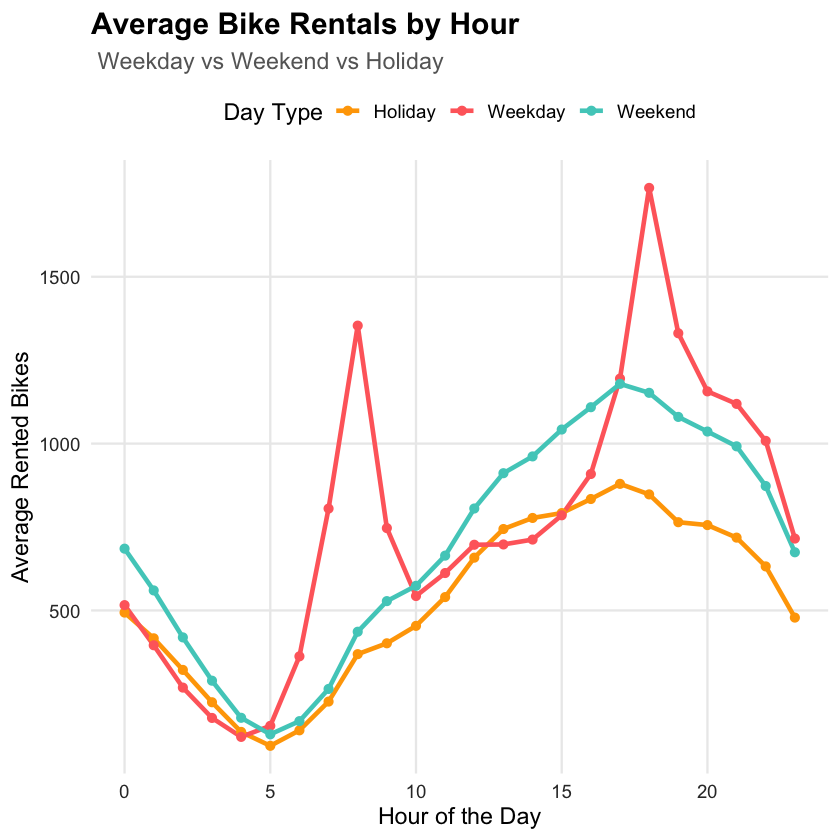

In [15]:
ggplot(seoul_bike_data, aes(x = Hour, y = `Rented Bike Count`, color = day_type)) +
  stat_summary(fun = mean, geom = "line", linewidth = 1.3) +
  stat_summary(fun = mean, geom = "point", size = 2) +
  labs(
    title = "Average Bike Rentals by Hour",
    subtitle = " Weekday vs Weekend vs Holiday",
    x = "Hour of the Day",
    y = "Average Rented Bikes",
    color = "Day Type"
  ) +
  scale_color_manual(values = c(
    "Weekday" = "#ff6b6b",
    "Weekend" = "#4ecdc4",
    "Holiday" = "#ffa600"
  )) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank(),
    legend.position = "top"
  )

In [16]:
seoul_bike_data %>%
  filter(Holiday == "Holiday") %>%
  group_by(Seasons) %>%
  summarise(holiday_days = n_distinct(Date)) %>%
  arrange(desc(holiday_days))

Seasons,holiday_days
<chr>,<int>
Winter,8
Autumn,4
Spring,3
Summer,2


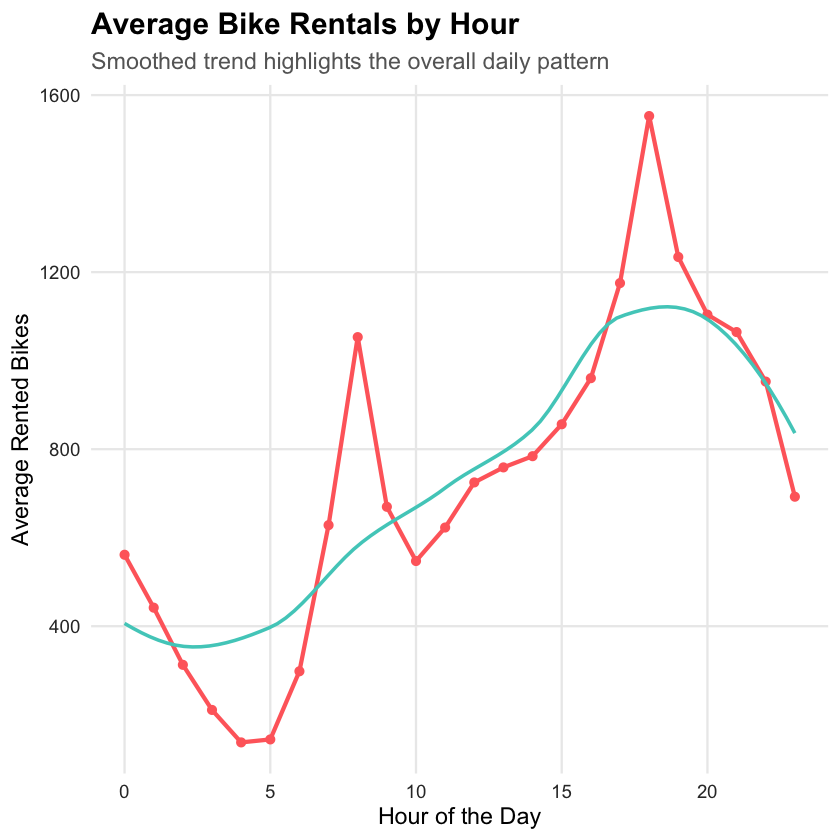

In [17]:
ggplot(seoul_bike_data, aes(x = Hour, y = `Rented Bike Count`)) +
  stat_summary(fun = mean, geom = "line", 
               color = "#ff6b6b", linewidth = 1.2) +
  stat_summary(fun = mean, geom = "point", 
               color = "#ff6b6b", size = 2) +
  geom_smooth(method = "loess", formula = y ~ x, se = FALSE,
              color = "#4ecdc4", linewidth = 1) +
  labs(
    title = "Average Bike Rentals by Hour",
    subtitle = "Smoothed trend highlights the overall daily pattern",
    x = "Hour of the Day",
    y = "Average Rented Bikes"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

A simple trend can be observed in bike rental demand across the days of the week. Demand remains relatively consistent throughout **weekdays**, while a noticeable decrease can be seen during the **weekend**.

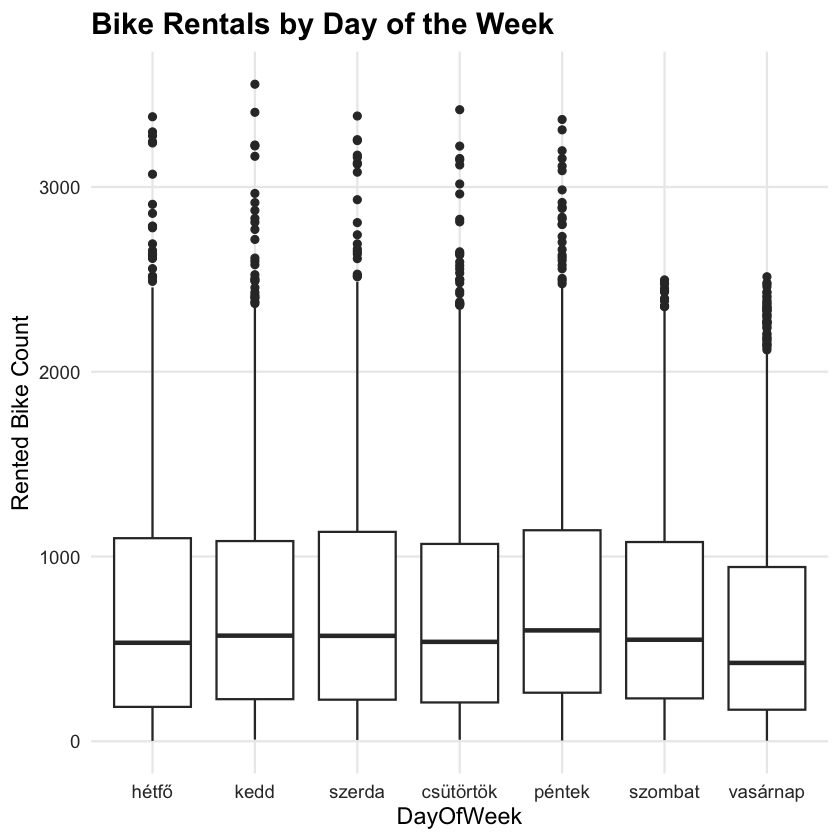

In [18]:
seoul_bike_data$DayOfWeek = factor(
    weekdays(seoul_bike_data$Date),
    levels = c("hétfő","kedd","szerda","csütörtök","péntek","szombat","vasárnap")
)

ggplot(seoul_bike_data, aes(x = DayOfWeek, y = `Rented Bike Count`)) +
    geom_boxplot() +
    labs(
        title = "Bike Rentals by Day of the Week"
    ) +
    theme_minimal(base_size = 14) +
    theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
)

A clear seasonal pattern can be observed in bike rental demand. The highest demand occurs during the **summer months**, while a significant decrease is visible in **winter**.

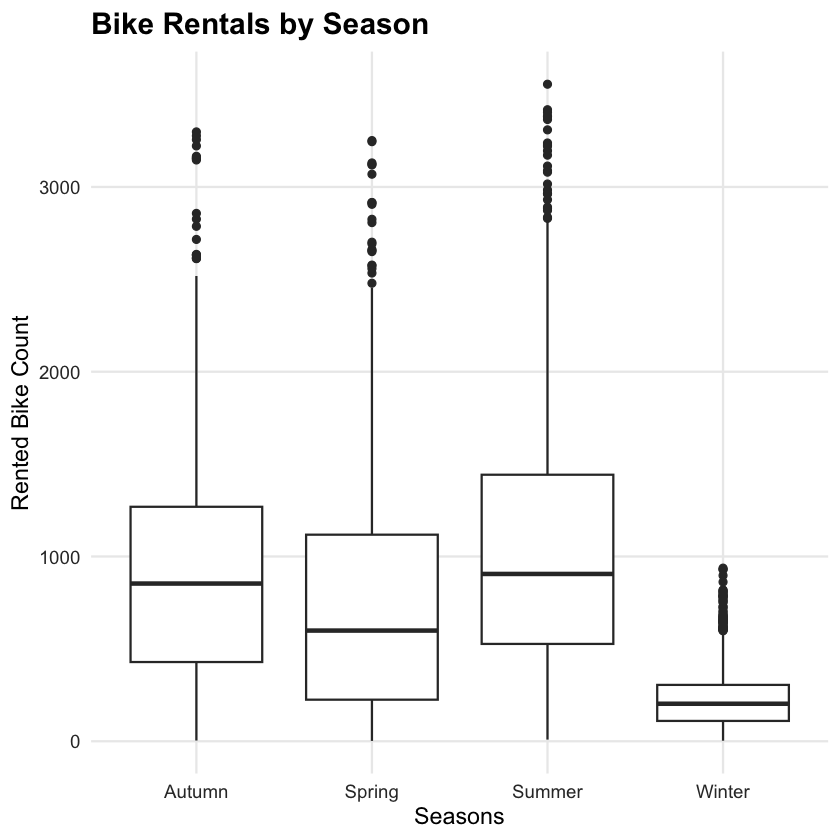

In [19]:
ggplot(seoul_bike_data, aes(x = Seasons, y = `Rented Bike Count`)) +
    geom_boxplot()+
    labs(
        title = "Bike Rentals by Season"
    )+
    theme_minimal(base_size = 14) +
    theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
)

### Impact of Weather Conditions on Bike Rentals

The seasonal boxplot already suggests that weather has a strong impact on bike rental demand, with noticeably lower usage during winter.
The following plots show that precipitation (*rain* and *snow*) significantly reduces the number of rentals.
Among the remaining **weather variables**, temperature also stands out as a strong feature influencing demand.

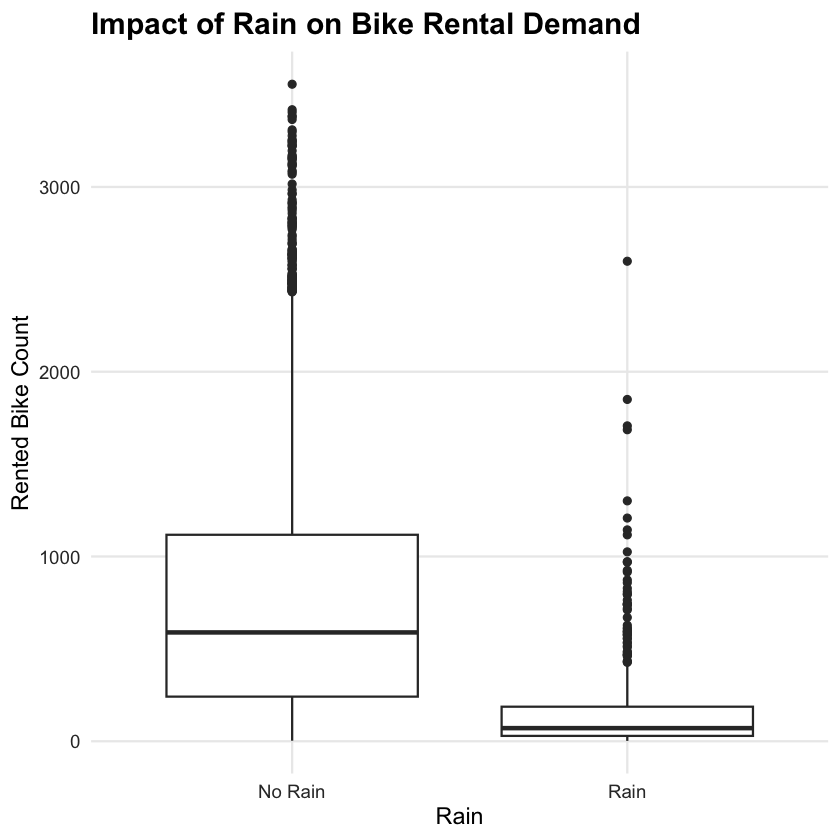

In [20]:
seoul_bike_data$Rain = ifelse(seoul_bike_data$`Rainfall(mm)` > 0, "Rain", "No Rain")

ggplot(seoul_bike_data, aes(x = Rain, y = `Rented Bike Count`)) +
    geom_boxplot() +
    labs(
        title = "Impact of Rain on Bike Rental Demand"
    ) +
    theme_minimal(base_size = 14) +
    theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
)

Examination of the relationship between **humidity**, **rainfall**, **snowfall**, **temperature**, **wind speed**, and **bike rental demand**.

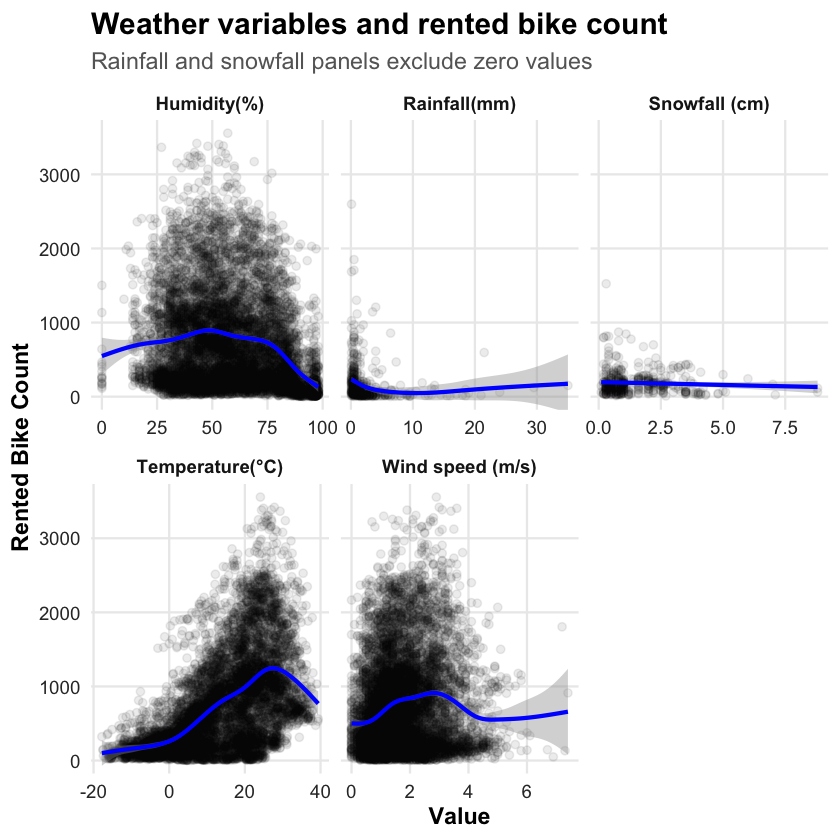

In [21]:
weather_data = seoul_bike_data %>%
  dplyr::select(
    `Rented Bike Count`,
    `Temperature(°C)`,
    `Humidity(%)`,
    `Wind speed (m/s)`,
    `Rainfall(mm)`,
    `Snowfall (cm)`
  ) %>%
  pivot_longer(
    cols = -`Rented Bike Count`,
    names_to = "Variable",
    values_to = "Value"
  )

weather_data_filtered = weather_data %>%
  filter(
    !(Variable == "Rainfall(mm)" & Value == 0),
    !(Variable == "Snowfall (cm)" & Value == 0)
  )

ggplot(weather_data_filtered, aes(x = Value, y = `Rented Bike Count`)) +
  geom_point(alpha = 0.08, color = "black") +
  geom_smooth(
    method = "gam",
    formula = y ~ s(x, bs = "cs"),
    color = "blue",
    linewidth = 1.2,
    se = TRUE
  ) +
  facet_wrap(~ Variable, scales = "free_x") +
  coord_cartesian(ylim = c(0, NA)) +
  labs(
    title = "Weather variables and rented bike count",
    subtitle = "Rainfall and snowfall panels exclude zero values",
    y = "Rented Bike Count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.title = element_text(face = "bold"),
    axis.text = element_text(color = "gray20"),
    strip.text = element_text(face = "bold"),
    panel.grid.minor = element_blank()
  )

Analysis of the relationship between key weather variables (*humidity*, *rainfall*, *snowfall*, *temperature*, and *wind speed*) and **bike rental demand**. The figure suggests a clear relationship between bike demand and weather conditions, with particularly strong effects observed for temperature and precipitation. Additionally, combinations of variables also appear to play a role, for example the interaction between **humidity** and **temperature**.

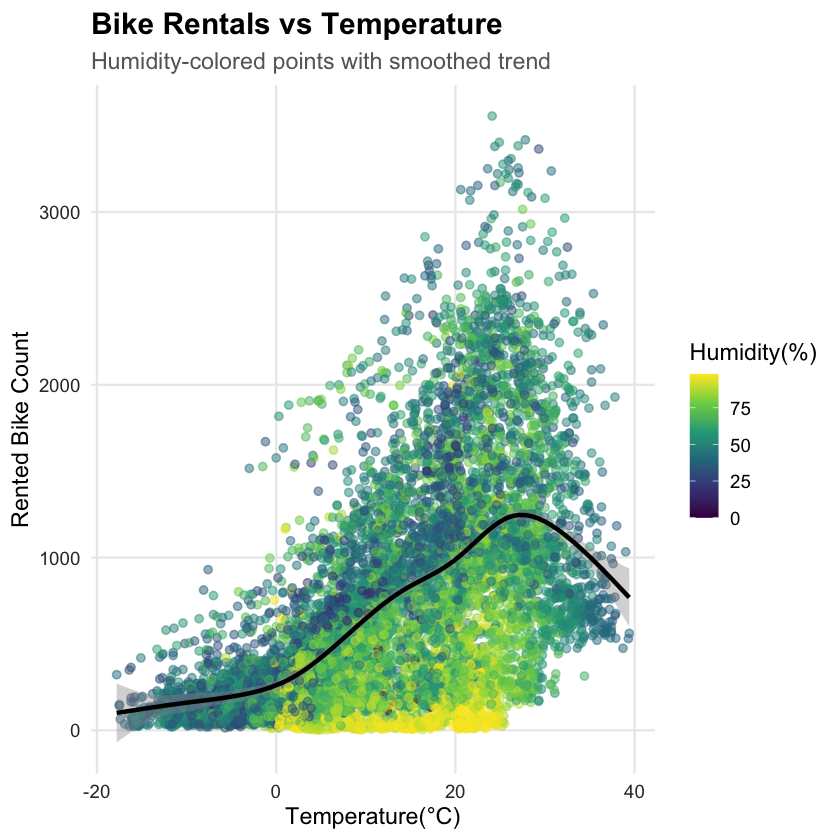

In [22]:
ggplot(seoul_bike_data,
       aes(x = `Temperature(°C)`,
           y = `Rented Bike Count`,
           color = `Humidity(%)`)) +
    geom_point(alpha = 0.5) +
    geom_smooth(method = "gam", formula = y ~ s(x, bs = "cs"), color = "black") +
    scale_color_viridis_c() +
    labs(
        title = "Bike Rentals vs Temperature",
        subtitle = "Humidity-colored points with smoothed trend"
    ) +
    theme_minimal(base_size = 14) +
    theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
)

### Autocorrelation

Autocorrelation was examined using the ***ACF*** plot to identify temporal dependencies in bike rental demand.
**Lag 1** shows a very strong correlation, indicating that the number of rentals in the previous hour is highly predictive of the current hour.
**Lag 24** is also significant, reflecting a daily pattern where rental demand at a given hour is similar to the same hour on the previous day.
**Lag 168** (one week) was also considered, but it is slightly weaker than **lag 24**.

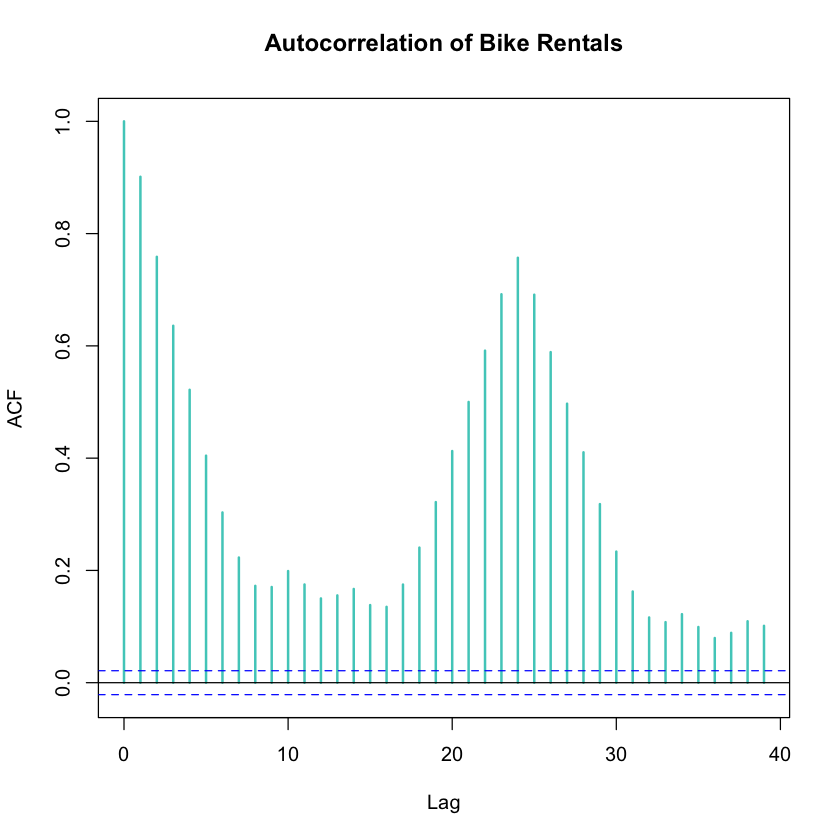

In [23]:
acf(
  seoul_bike_data$`Rented Bike Count`,
  col = "#4ecdc4",
  lwd = 2,
  main = "Autocorrelation of Bike Rentals"
)

Analysis of temporal dependency in bike rental demand using a lag plot. The results indicate that the previous hour’s demand (***lag1***) has strong predictive power for the current value. Nevertheless, as the objective of this project is to generate forecasts at least one day ahead, a one-hour lag is considered too short for the intended task.

`geom_smooth()` using formula = 'y ~ x'


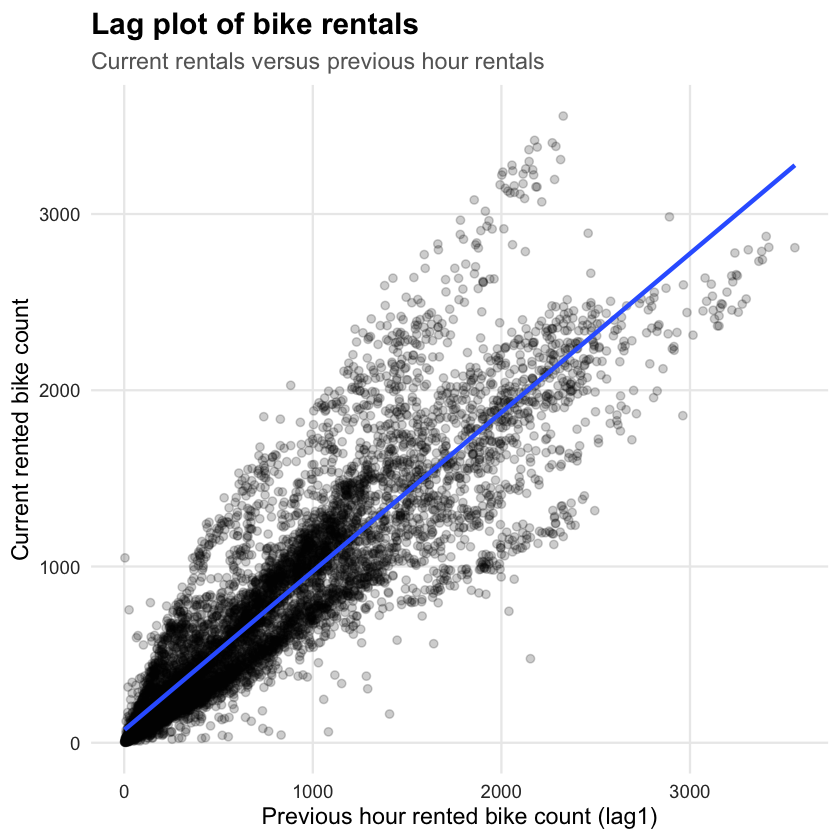

In [24]:
seoul_bike_data = seoul_bike_data %>%
  arrange(Date, Hour) %>%
  mutate(lag1 = lag(`Rented Bike Count`, 1))

ggplot(seoul_bike_data %>% filter(!is.na(lag1)),
       aes(x = lag1, y = `Rented Bike Count`)) +
  geom_point(alpha = 0.2) +
  geom_smooth(method = "lm", se = FALSE) +
  labs(
    title = "Lag plot of bike rentals",
    subtitle = "Current rentals versus previous hour rentals",
    x = "Previous hour rented bike count (lag1)",
    y = "Current rented bike count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

Analysis of temporal dependency using a 24-hour lag (***lag24***). The figure indicates that the previous day’s demand at the same hour is still a useful predictor of current demand, although the relationship is weaker compared to the one-hour lag.

`geom_smooth()` using formula = 'y ~ x'


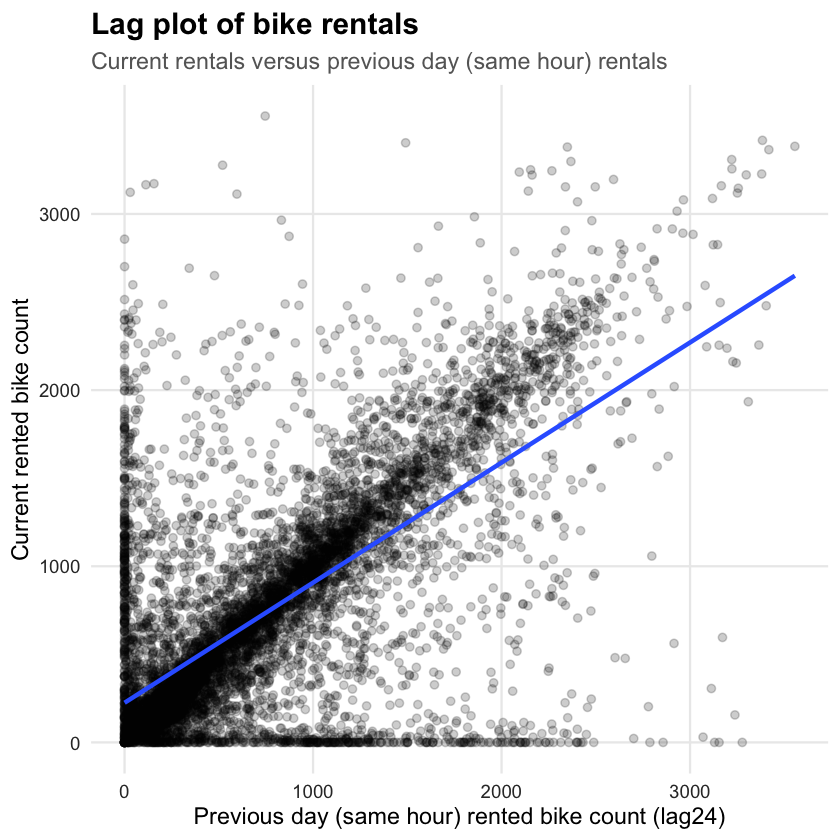

In [62]:
seoul_bike_data = seoul_bike_data %>%
  arrange(Date, Hour) %>%
  mutate(lag24 = lag(`Rented Bike Count`, 24))

ggplot(seoul_bike_data %>% filter(!is.na(lag24)),
       aes(x = lag24, y = `Rented Bike Count`)) +
  geom_point(alpha = 0.2) +
  geom_smooth(method = "lm", se = FALSE) +
  labs(
    title = "Lag plot of bike rentals",
    subtitle = "Current rentals versus previous day (same hour) rentals",
    x = "Previous day (same hour) rented bike count (lag24)",
    y = "Current rented bike count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

Analysis of temporal dependency using a 168-hour lag (***lag168***). The figure indicates that the previous week’s demand at the same hour still contains some predictive information, although the relationship is weaker compared to the one-day lag.

`geom_smooth()` using formula = 'y ~ x'


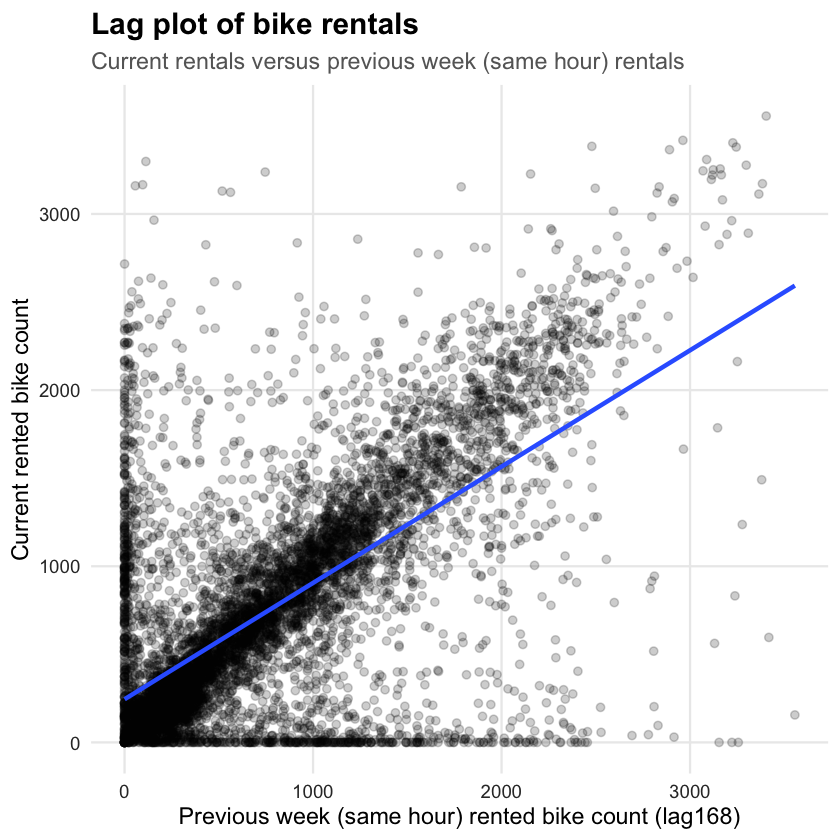

In [63]:
seoul_bike_data = seoul_bike_data %>%
  arrange(Date, Hour) %>%
  mutate(lag168 = lag(`Rented Bike Count`, 168))

ggplot(seoul_bike_data %>% filter(!is.na(lag168)),
       aes(x = lag168, y = `Rented Bike Count`)) +
  geom_point(alpha = 0.2) +
  geom_smooth(method = "lm", se = FALSE) +
  labs(
    title = "Lag plot of bike rentals",
    subtitle = "Current rentals versus previous week (same hour) rentals",
    x = "Previous week (same hour) rented bike count (lag168)",
    y = "Current rented bike count"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

Based on the observed temporal dependencies, the 24-hour lag (***lag24***) will be used as an input feature in the ***Random Forest model***, as it provides a good balance between predictive power and alignment with the project’s forecasting horizon.

### 24-hour Rolling Mean

The 24-hour rolling mean represents the average bike rental demand over the previous 24 hours, providing a smoothed view of the data by reducing short-term fluctuations.

Seasonal patterns are clearly visible, with higher demand in **warmer** periods.

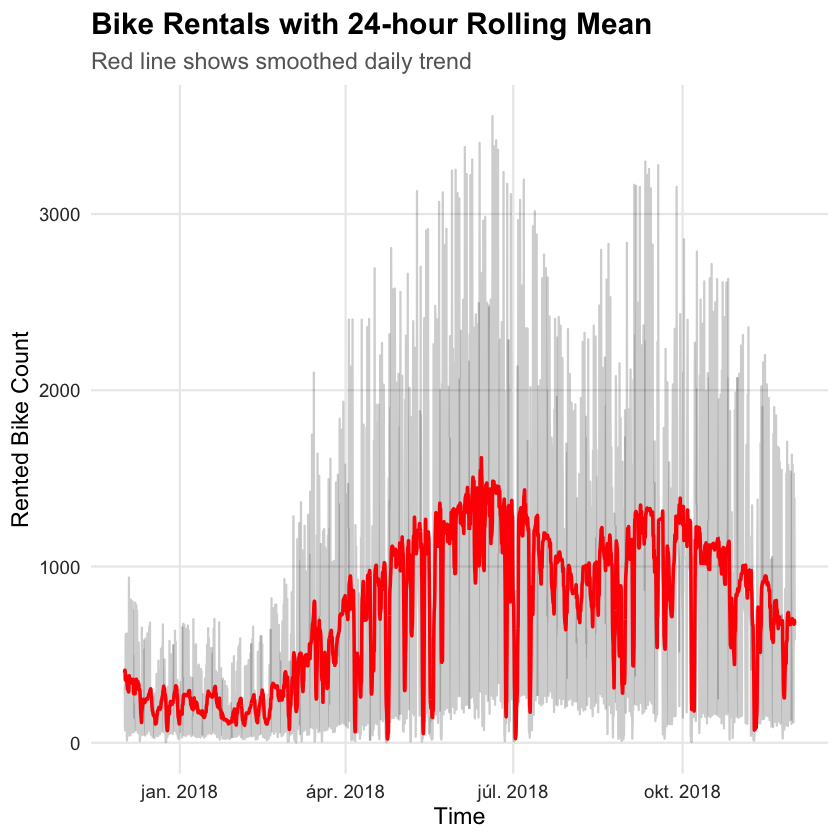

In [27]:
seoul_bike_data = seoul_bike_data %>%
  arrange(Date, Hour) %>%
  mutate(
    datetime = as.POSIXct(
      paste(Date, sprintf("%02d", Hour)),
      format = "%Y-%m-%d %H",
      tz = "Asia/Seoul"
    ),
    lag1 = lag(`Rented Bike Count`, 1),
    lag24 = lag(`Rented Bike Count`, 24),
    rollmean_24 = zoo::rollmean(`Rented Bike Count`, 24, fill = NA, align = "right")
  )

plot_data = seoul_bike_data %>%
  filter(!is.na(rollmean_24))

ggplot(plot_data, aes(x = datetime)) +
  geom_line(aes(y = `Rented Bike Count`), alpha = 0.2) +
  geom_line(aes(y = rollmean_24), color = "red", linewidth = 1) +
  labs(
    title = "Bike Rentals with 24-hour Rolling Mean",
    subtitle = "Red line shows smoothed daily trend",
    x = "Time",
    y = "Rented Bike Count"
  ) +
  theme_minimal(base_size = 14) + 
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

### Correlation Matrix

The correlation matrix highlights strong relationships between bike rentals and lag features, especially ***lag1***, ***lag24***, and ***lag168***, confirming temporal dependencies in the data.
Temperature and dew point temperature are also highly correlated with each other, indicating that they capture very similar information.

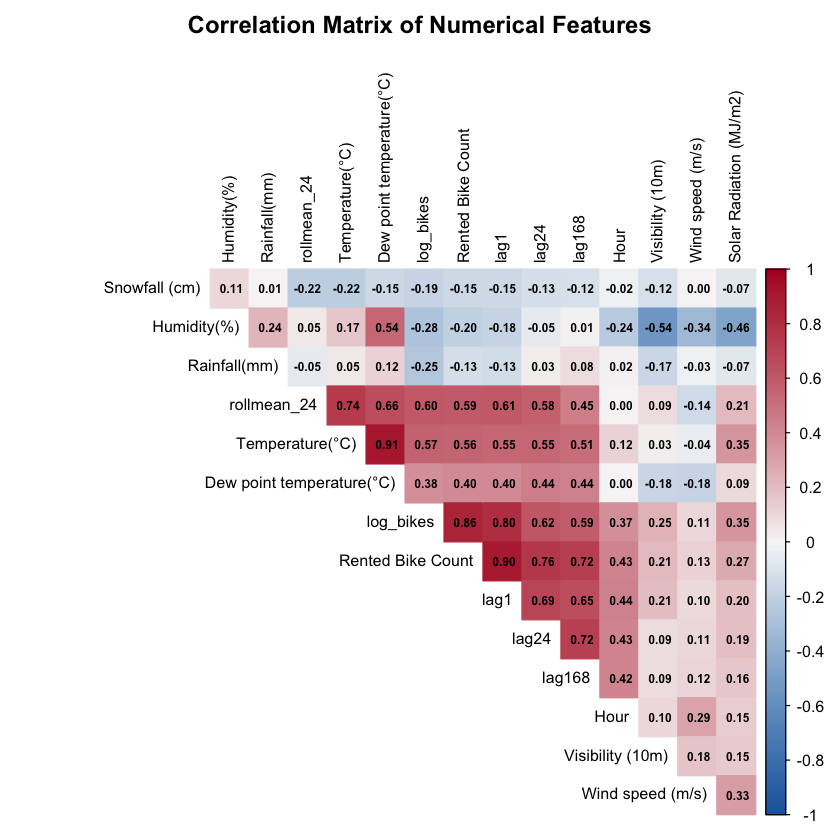

In [28]:
numeric_data = seoul_bike_data %>%
  dplyr::select(where(is.numeric))

cor_matrix = cor(numeric_data, use = "complete.obs")

corrplot(
  cor_matrix,
  method = "color",
  type = "upper",
  order = "hclust",             
  addCoef.col = "black",
  tl.col = "black",
  tl.cex = 0.8,
  number.cex = 0.6,
  col = colorRampPalette(c("#2166ac", "#f7f7f7", "#b2182b"))(200), 
  diag = FALSE,
  addgrid.col = NA,
  mar = c(0,0,2,0),
  title = "Correlation Matrix of Numerical Features"
)

## Supervised Learning Model Building and Evaluation

In this section, I used the **Random Forest model** to predict rented bike count.
Model performance is evaluated using **RMSE**, **MAE**, and **R²** metrics.

In [29]:
head(seoul_bike_data, 2)

Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),⋯,log_bikes,is_weekend,day_type,DayOfWeek,Rain,lag1,lag24,lag168,datetime,rollmean_24
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<lgl>,<chr>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dttm>,<dbl>
2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0,0,⋯,5.541264,FALSE,Weekday,péntek,No Rain,NA,NA,NA,2017-12-01 00:00:00,NA
2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0,0,⋯,5.323010,FALSE,Weekday,péntek,No Rain,254,NA,NA,2017-12-01 01:00:00,NA


In [30]:
seoul_bike_data_rf = seoul_bike_data %>%
drop_na(lag1, lag24, lag168, rollmean_24)

The dataset is split into training and test sets based on time to preserve the temporal structure of the data. 

Additionally, a **rolling-origin** resampling strategy is applied to the training set to perform time series **cross-validation**. In this approach, each fold is created by using an initial training window of 120 days (24 × 120 hours), followed by an assessment window of 30 days (24 × 30 hours). The training window is cumulative, meaning it expands with each iteration, while the evaluation window moves forward in time in 30-day steps. This method preserves the temporal ordering of the data and ensures that the model is always evaluated on future observations relative to the training data, making it well-suited for time series forecasting tasks.

In [31]:
set.seed(123)

train <- seoul_bike_data_rf %>%
filter(datetime < as.POSIXct("2018-10-01"))

test <- seoul_bike_data_rf %>%
filter(datetime >= as.POSIXct("2018-10-01"))

In [32]:
time_folds <- rolling_origin(
  data = train,
  initial = 24 * 120,
  assess = 24 * 30,
  skip = 24 * 30,
  cumulative = TRUE
)

Features created only for visualization and those considered noisy were excluded from the model, while variables that proved useful during data exploration were retained.

**Lag1** was excluded from the model because, although it is a strong feature, the goal is to predict demand at least one day ahead rather than just the next hour.

Additionally, cyclical transformations of the Hour variable were introduced using sine and cosine functions (***sin_hour*** and ***cos_hour***) to capture the periodic nature of daily patterns. This approach allows the model to better represent the circular structure of time, where, for example, hour 23 and hour 0 are close to each other.

Categorical variables such as ***day_type*** are converted into dummy variables using one-hot encoding

In [33]:
bike_recipe = recipe(`Rented Bike Count` ~ ., data = train) %>%
step_rm(Date, `Functioning Day`, log_bikes, `Dew point temperature(°C)`,
        Seasons, Rain, DayOfWeek, is_weekend, `Visibility (10m)`, `Solar Radiation (MJ/m2)`,
        `Wind speed (m/s)`, rollmean_24, lag1, lag168) %>%
step_mutate(
    sin_hour = sin(2 * pi * Hour / 24),
    cos_hour = cos(2 * pi * Hour / 24)
) %>%
step_dummy(all_nominal_predictors()) %>%
step_zv(all_predictors())

A **Random Forest model** is defined and integrated into a workflow along with the preprocessing steps. Parameter tuning is performed using a grid search over key parameters, including the number of variables considered at each split (*mtry*), the number of trees, and the minimum number of observations required to split a node (*min_n*). The model is evaluated using rolling-origin cross-validation, and the optimal parameter combination is selected based on **RMSE**.

In [34]:
rf_model = rand_forest(
  mtry = tune(),
  trees = tune(),
  min_n = tune()
) %>%
  set_engine("ranger", importance = "impurity") %>%
  set_mode("regression")

In [35]:
rf_workflow = workflow() %>%
  add_recipe(bike_recipe) %>%
  add_model(rf_model)

In [36]:
rf_grid <- grid_regular(
  mtry(range = c(2, 10)),
  trees(range = c(300, 800)),
  min_n(range = c(5, 30)),
  levels = 3
)

In [37]:
set.seed(123)

rf_tune_results <- tune_grid(
  rf_workflow,
  resamples = time_folds,
  grid = rf_grid,
  metrics = metric_set(rmse, mae, rsq)
)

best_rf_params <- select_best(rf_tune_results, metric = "rmse")

best_rf_params

mtry,trees,min_n,.config
<int>,<int>,<int>,<chr>
6,800,5,pre0_mod16_post0


In [38]:
final_rf_workflow <- finalize_workflow(
  rf_workflow,
  best_rf_params
)

In [39]:
final_rf_resamples <- fit_resamples(
  final_rf_workflow,
  resamples = time_folds,
  metrics = metric_set(rmse, mae, rsq),
  control = control_resamples(save_pred = TRUE)
)

The cross-validation results indicate that the **Random Forest** model achieves a reasonably good predictive performance. The RMSE (343.58) and MAE (242.10) suggest a moderate level of prediction error in absolute terms. The R² value of 0.76 indicates that the model explains approximately 76% of the variance in bike rental demand, demonstrating a good overall fit.

In [52]:
cv_predictions <- collect_predictions(final_rf_resamples) %>%
  rename(
    actual = `Rented Bike Count`,
    predicted = .pred
  )

cv_metrics <- metric_set(rmse, mae, rsq)(
  cv_predictions,
  truth = actual,
  estimate = predicted
)

cv_metrics

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
rmse,standard,343.5841130
mae,standard,242.0993454
rsq,standard,0.7571462


The performance of the **Random Forest** model on the test set indicates a strong predictive capability. The RMSE (193.74) and MAE (136.46) show a relatively low prediction error, while the R² value of 0.89 suggests that the model explains approximately 89% of the variance in bike rental demand. Overall, the model **demonstrates good generalization performance on unseen data**.

In [53]:
final_rf_fit <- final_rf_workflow %>%
  fit(data = train)

test_predictions <- predict(final_rf_fit, new_data = test) %>%
  bind_cols(test %>% dplyr::select(datetime, `Rented Bike Count`)) %>%
  rename(
    predicted = .pred,
    actual = `Rented Bike Count`
  )

test_metrics <- metric_set(rmse, mae, rsq)(
  test_predictions,
  truth = actual,
  estimate = predicted
)

test_metrics

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
rmse,standard,193.7369373
mae,standard,136.4599086
rsq,standard,0.8875466


The figure compares the actual and predicted bike rental demand over time. The Random Forest model closely follows the overall trend and captures most of the fluctuations in the data, although some deviations can be observed during **peak periods**.

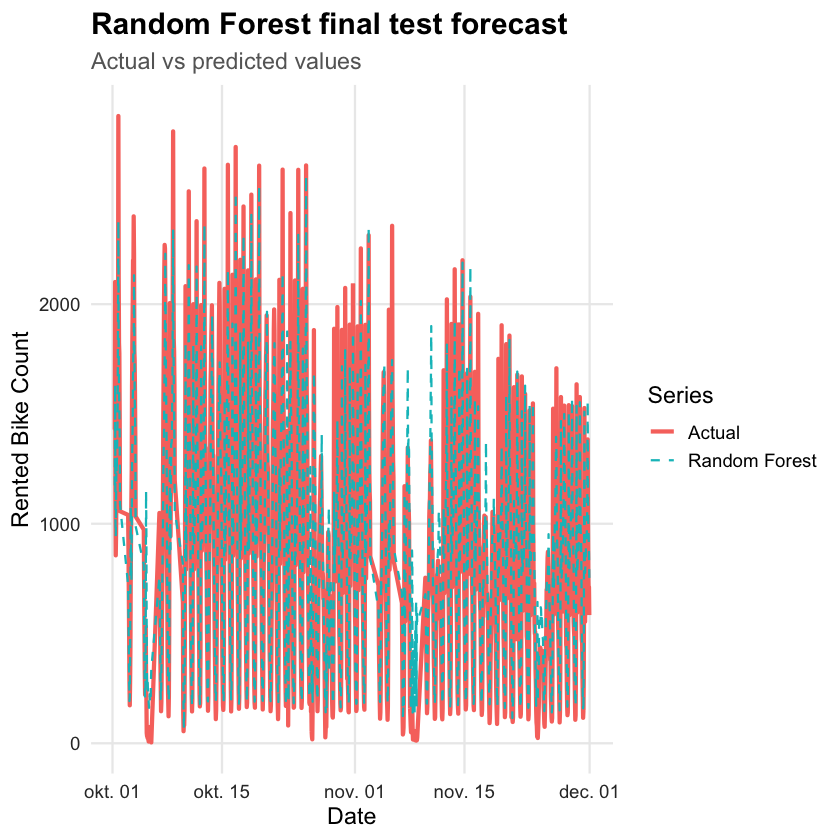

In [42]:
ggplot(test_predictions, aes(x = datetime)) +
  geom_line(aes(y = actual, color = "Actual"), linewidth = 1.2) +
  geom_line(aes(y = predicted, color = "Random Forest"), linetype = "dashed") +
  labs(
    title = "Random Forest final test forecast",
    subtitle = "Actual vs predicted values",
    x = "Date",
    y = "Rented Bike Count",
    color = "Series"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

Since the previous figure is somewhat dense, the forecast is visualized over a one-week period for better clarity. It can be clearly observed that the model successfully captures the lower demand during weekends, while also closely following the higher and more stable demand during weekdays.

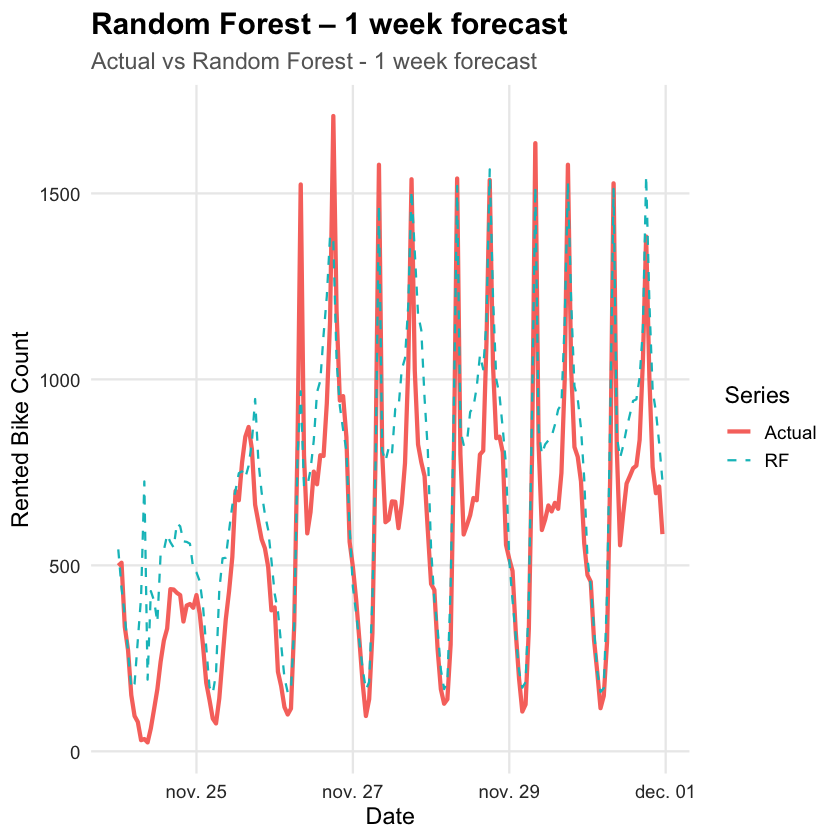

In [61]:
plot_week <- test_predictions %>%
  dplyr::slice_tail(n = 24 * 7)

ggplot(plot_week, aes(x = datetime)) +
  geom_line(aes(y = actual, color = "Actual"), linewidth = 1.2) +
  geom_line(aes(y = predicted, color = "RF"), linetype = "dashed") +
  labs(
    title = "Random Forest – 1 week forecast",
    subtitle = "Actual vs Random Forest - 1 week forecast",
    x = "Date",
    y = "Rented Bike Count",
    color = "Series"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

## Time Series Model Building and Evaluation

In the following section, time series–specific models are examined, including **ARIMA**, **Seasonal ARIMA**, and **VAR**.

In [43]:
bike_ts = seoul_bike_data %>%
    pull(`Rented Bike Count`)
bike_ts = ts(bike_ts, frequency = 24)

The figure shows the decomposition of the bike rental time series into its components. The trend indicates that bike demand increases over time, reaches a peak, and then gradually declines. The seasonal component reveals a strong and consistent daily pattern, reflecting the hourly usage cycle. The random component captures irregular fluctuations that are not explained by the trend or seasonality.

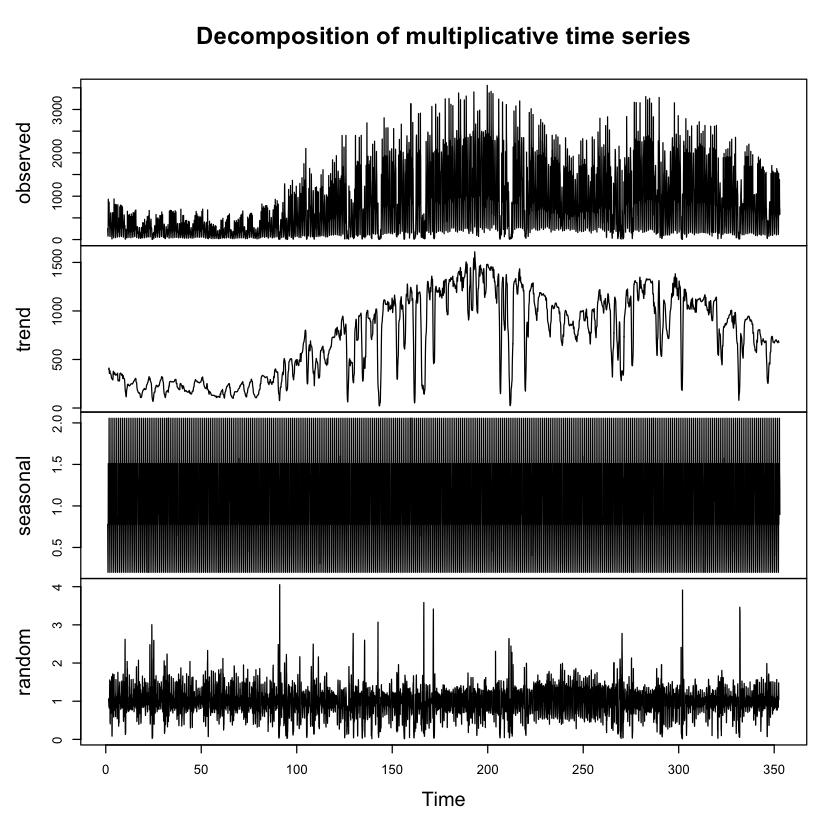

In [44]:
decomp = decompose(bike_ts, type = "multiplicative")

plot(decomp)

**ARIMA** and **SARIMA** models are fitted on the training data to produce 24-hour forecasts, and their performance is evaluated on the test set using **RMSE**, **MAE**, and **MAPE**.

In [45]:
h = 24

bike_vec = as.numeric(bike_ts)

train_vec = bike_vec[1:(length(bike_vec) - h)]
test_vec  = bike_vec[(length(bike_vec) - h + 1):length(bike_vec)]

train_ts = ts(train_vec, frequency = 24)

# ARIMA
arima_model <- auto.arima(
  train_ts,
  seasonal = FALSE,
  stepwise = TRUE,
  approximation = TRUE
)

# SARIMA
sarima_model <- auto.arima(
  train_ts,
  seasonal = TRUE,
  stepwise = TRUE,
  approximation = TRUE,
  max.p = 3,
  max.q = 3,
  max.P = 1,
  max.Q = 1
)

arima_fc = forecast(arima_model, h = h)
sarima_fc = forecast(sarima_model, h = h)

arima_acc = forecast::accuracy(arima_fc$mean, test_vec)
sarima_acc = forecast::accuracy(sarima_fc$mean, test_vec)

results_ts <- data.frame(
  Model = c("ARIMA", "SARIMA"),
  RMSE = c(
    arima_acc["Test set", "RMSE"],
    sarima_acc["Test set", "RMSE"]
  ),
  MAE = c(
    arima_acc["Test set", "MAE"],
    sarima_acc["Test set", "MAE"]
  ),
  MAPE = c(
    arima_acc["Test set", "MAPE"],
    sarima_acc["Test set", "MAPE"]
  )
)

A **VAR** model is fitted using bike demand and weather variables, with the optimal lag selected via **AIC**. The model generates forecasts for the test set, which are evaluated using **RMSE**, **MAE**, and **MAPE**.

In [46]:
var_data <- seoul_bike_data %>%
  dplyr::select(
    rented = `Rented Bike Count`,
    `Temperature(°C)`,
    `Wind speed (m/s)`,
    `Rainfall(mm)`,
    `Snowfall (cm)`
  ) %>%
  na.omit()

train_var = head(var_data, nrow(var_data) - h)
test_var = tail(var_data, h)

lag_select = VARselect(train_var, lag.max = 24)

best_lag = as.numeric(lag_select$selection["AIC(n)"])

var_model = VAR(train_var, p = best_lag)

var_fc = predict(var_model, n.ahead = nrow(test_var))

pred_var = as.numeric(var_fc$fcst$rented[, "fcst"])
actual_var = test_var$rented

var_acc = forecast::accuracy(pred_var, actual_var)

var_results <- data.frame(
  Model = "VAR",
  RMSE = var_acc["Test set", "RMSE"],
  MAE = var_acc["Test set", "MAE"],
  MAPE = var_acc["Test set", "MAPE"]
)

**SARIMA** significantly **outperforms** both **ARIMA** and **VAR**, indicating that capturing seasonality is crucial. VAR shows **moderate performance**, while ARIMA performs **the worst**.

In [47]:
final_results <- rbind(
  results_ts,
  var_results
)

final_results

Model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
ARIMA,336.07406,255.68434,68.543144
SARIMA,62.77215,48.05914,7.002295
VAR,177.49133,114.58636,22.524246


The figure clearly shows that the **SARIMA** model closely follows the **24-hour demand pattern**, capturing both the trend and fluctuations accurately. In contrast, the **ARIMA** and **VAR** models perform significantly worse.

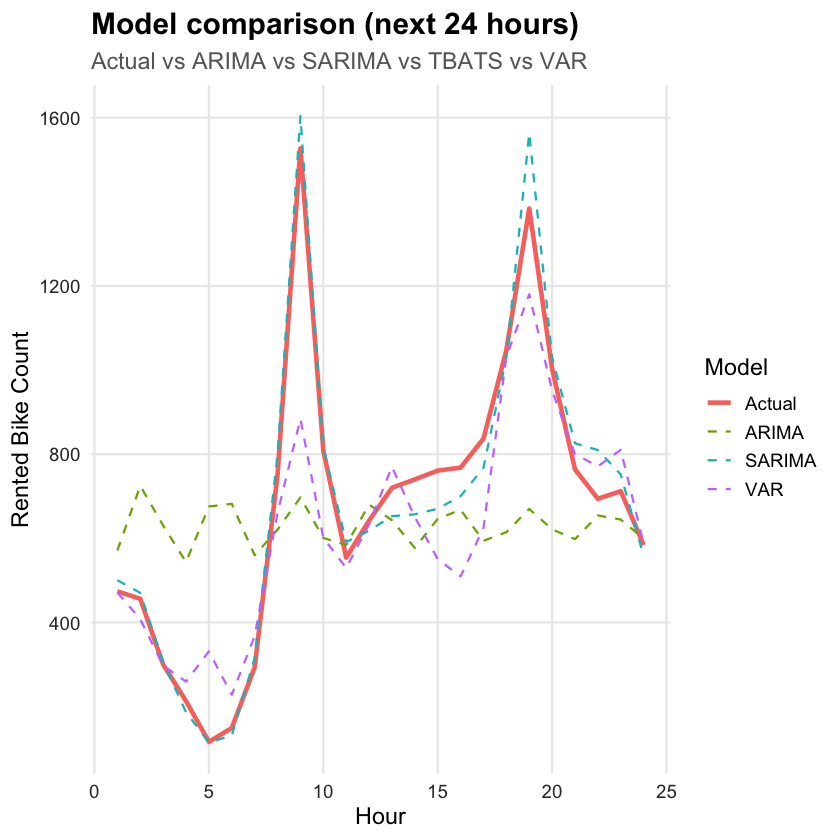

In [48]:
pred_arima = as.numeric(arima_fc$mean)
pred_sarima = as.numeric(sarima_fc$mean)
pred_var = as.numeric(var_fc$fcst$rented[, "fcst"])

time_index = 1:h

df_plot = data.frame(
  time = time_index,
  actual = test_vec,
  ARIMA = pred_arima,
  SARIMA = pred_sarima,
  VAR = pred_var
)

ggplot(df_plot, aes(x = time)) +
  geom_line(aes(y = actual, color = "Actual"), linewidth = 1.3) +
  geom_line(aes(y = ARIMA, color = "ARIMA"), linetype = "dashed") +
  geom_line(aes(y = SARIMA, color = "SARIMA"), linetype = "dashed") +
  geom_line(aes(y = VAR, color = "VAR"), linetype = "dashed") +
  labs(
    title = "Model comparison (next 24 hours)",
    subtitle = "Actual vs ARIMA vs SARIMA vs TBATS vs VAR",
    x = "Hour",
    y = "Rented Bike Count",
    color = "Model"
  ) +
  theme_minimal(base_size = 14) + 
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

The performance of the **SARIMA** model was also evaluated for a **one-week forecasting horizon**. The results show a noticeable decrease in accuracy compared to the **24-hour forecast**, with higher **RMSE**, **MAE**, and **MAPE** values, indicating that longer-term predictions are more challenging.

In [55]:
h_week = 168

bike_vec = as.numeric(bike_ts)

train_vec_week = bike_vec[1:(length(bike_vec) - h_week)]
test_vec_week  = bike_vec[(length(bike_vec) - h_week + 1):length(bike_vec)]

train_ts_week = ts(train_vec_week, frequency = 24)

sarima_week_model <- auto.arima(
  train_ts_week,
  seasonal = TRUE,
  stepwise = TRUE,
  approximation = TRUE,
  max.p = 3,
  max.q = 3,
  max.P = 1,
  max.Q = 1
)

sarima_week_fc = forecast(sarima_week_model, h = h_week)

sarima_week_acc = forecast::accuracy(
  sarima_week_fc$mean,
  test_vec_week
)

sarima_week_results <- data.frame(
  Model = "SARIMA - 1 week",
  RMSE = sarima_week_acc["Test set", "RMSE"],
  MAE = sarima_week_acc["Test set", "MAE"],
  MAPE = sarima_week_acc["Test set", "MAPE"]
)

sarima_week_results

Model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
SARIMA - 1 week,265.0655,128.087,101.4681


Comparing the one-week forecasts of the **Random Forest** and **SARIMA** models, it can be observed that while the **SARIMA** model fits the weekday patterns well, it tends to overestimate demand during weekends, treating them similarly to weekdays. In contrast, the **Random Forest** model, although slightly less precise overall, captures the difference between weekdays and weekends more effectively and follows the weekly pattern more accurately. This behavior can be explained by the fact that the SARIMA model was configured with a seasonal frequency of **24 hours**, allowing it to capture daily patterns effectively, but limiting its ability to model longer-term weekly seasonality.

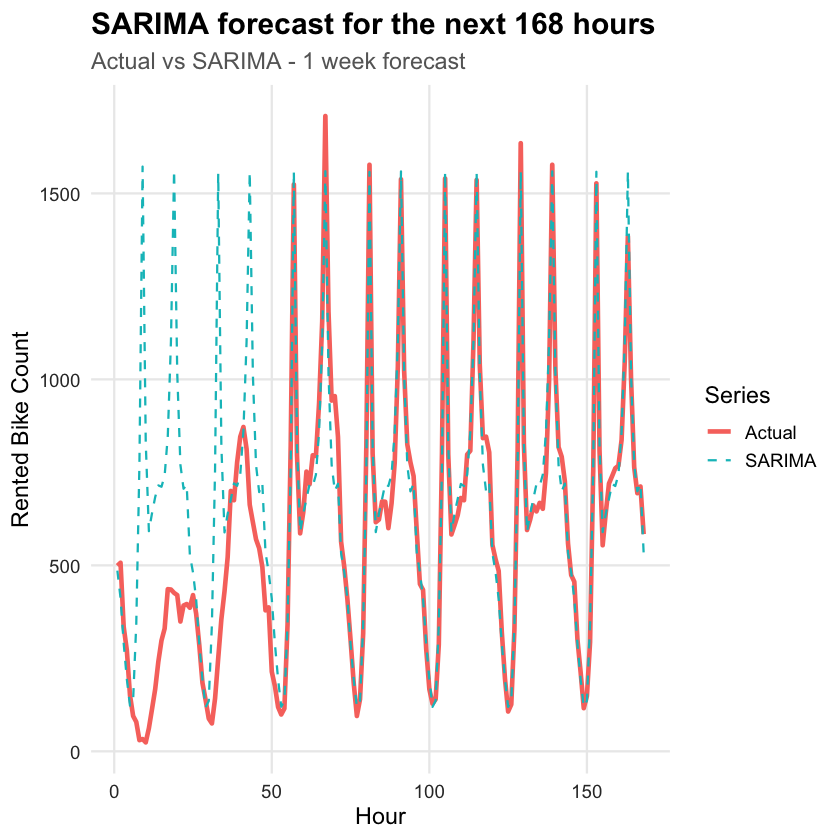

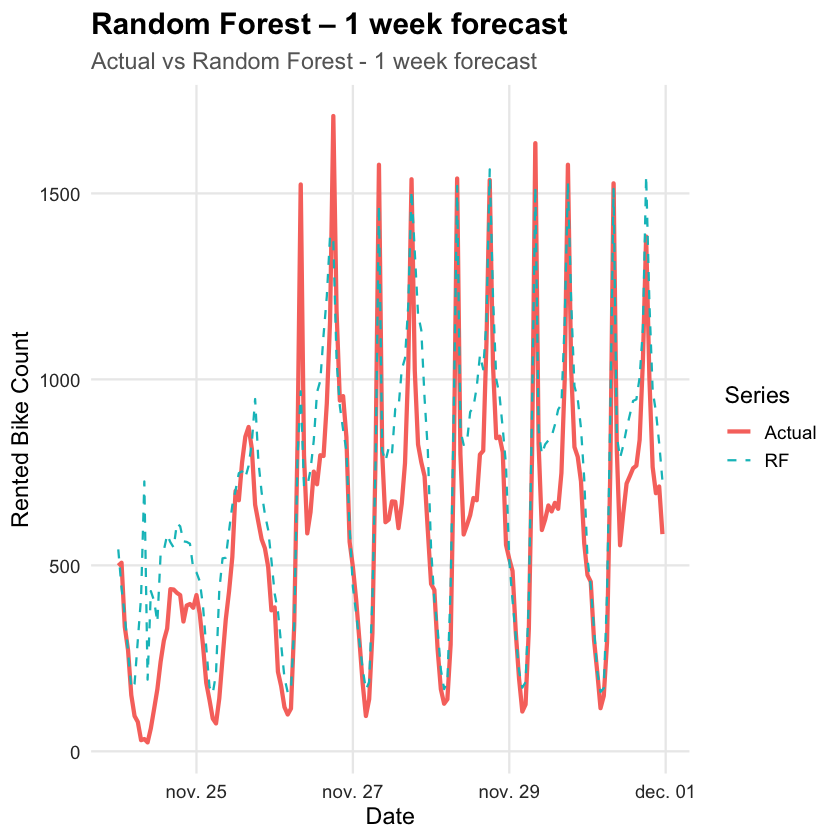

In [60]:
pred_sarima_week = as.numeric(sarima_week_fc$mean)

time_index_week = 1:h_week

df_plot_week = data.frame(
  time = time_index_week,
  actual = test_vec_week,
  SARIMA = pred_sarima_week
)

ggplot(df_plot_week, aes(x = time)) +
  geom_line(aes(y = actual, color = "Actual"), linewidth = 1.3) +
  geom_line(aes(y = SARIMA, color = "SARIMA"), linetype = "dashed") +
  labs(
    title = "SARIMA forecast for the next 168 hours",
    subtitle = "Actual vs SARIMA - 1 week forecast",
    x = "Hour",
    y = "Rented Bike Count",
    color = "Series"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

plot_week <- test_predictions %>%
  dplyr::slice_tail(n = 24 * 7)

ggplot(plot_week, aes(x = datetime)) +
  geom_line(aes(y = actual, color = "Actual"), linewidth = 1.2) +
  geom_line(aes(y = predicted, color = "RF"), linetype = "dashed") +
  labs(
    title = "Random Forest – 1 week forecast",
    subtitle = "Actual vs Random Forest - 1 week forecast",
    x = "Date",
    y = "Rented Bike Count",
    color = "Series"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold", size = 18),
    plot.subtitle = element_text(color = "gray40"),
    axis.text = element_text(color = "gray20"),
    panel.grid.minor = element_blank()
  )

## Final Conclusions

In conclusion, while the **SARIMA** model was able to accurately capture the daily pattern of bike demand and performed very well for typical weekdays, it struggled to correctly estimate demand during weekends. In contrast, the **Random Forest model**, despite not being a time series–specific approach, provided more consistent and accurate predictions over a one-week horizon.

This suggests that although the dataset has a strong time series structure, bike demand is influenced by multiple factors, including daily, weekly, and seasonal patterns, as well as weather conditions. As a result, a flexible machine learning model such as Random Forest, which can incorporate a wide range of features, **can outperform classical time series models** in this context.